# НИРМ3 — неделя 9: сравнение всех моделей и интерпретация

Использует предсказания XGBoost (неделя 4) и глубоких моделей недель 7–8 (`cache/results/`, обучены на
Colab), а для интерпретации — их веса, загружаемые на CPU через `ecg_models.py`.

Задачи недели 9 (календарный план):
1. Сравнение всех моделей года 2 — классический XGBoost и CNN / LSTM / Transformer — на одном тестовом
   фолде по метрикам ИПРМ: ROC-AUC, PR-AUC, precision, recall, F1, accuracy; разрыв по полу.
2. Рекомендации по выбору метода.
3. Интерпретация: карты внимания (CNN-LSTM) и Grad-CAM (CNN-LSTM, ResNet1d) для MI; проверка, что карты
   отражают работу модели (тест удаления) и куда они смотрят (QRS, ST-T).
4. Различаются ли объяснения у мужчин и женщин — мотив года 1 на сырых ЭКГ.

In [1]:
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.signal import find_peaks
from scipy.stats import mannwhitneyu, rankdata, spearmanr
from sklearn.metrics import average_precision_score

from ecg_models import load_model

SEED = 42
CACHE = 'cache' + os.sep
FIG_DIR = CACHE + 'fig' + os.sep
RESULTS = CACHE + 'results' + os.sep
assert glob.glob(RESULTS + '*.json'), 'скачайте results/ из Google Drive (см. ноутбук Colab)'
plt.rcParams.update({'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})
SEX_COLORS = {'male': '#4C72B0', 'female': '#C44E52'}
SUPERCLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
K_MI = SUPERCLASSES.index('MI')
torch.manual_seed(SEED)

meta = np.load(CACHE + 'colab_meta.npz')
Y, split, has_label, sex = meta['Y'].astype(int), meta['split'], meta['has_label'], meta['sex']
LEADS = json.load(open(CACHE + 'preprocessing.json'))['leads']
LEAD_MEAN, LEAD_STD = meta['lead_mean'].astype(np.float32), meta['lead_std'].astype(np.float32)
FS = int(meta['fs'])
va, te = [np.where((split == s) & has_label)[0] for s in ('val', 'test')]
y_va, y_te, sex_te = Y[va], Y[te], sex[te]

RUNS = {}
for f in sorted(glob.glob(RESULTS + '*.json')):
    info = json.load(open(f))
    z = np.load(f.replace('.json', '.npz'))
    assert np.array_equal(z['val_idx'], va) and np.array_equal(z['test_idx'], te)
    RUNS[info['run_id']] = {**info, 's_val': z['s_val'], 's_test': z['s_test'],
                            'weights': f.replace('.json', '_weights.pt')}
xgb = np.load(CACHE + 'xgb_scores.npz')
print(f'прогонов глубоких моделей: {len(RUNS)}; тест {len(te)} записей')

прогонов глубоких моделей: 19; тест 2158 записей


## Задача 1. Сравнение всех моделей

Для моделей с тремя seed метрики усредняются по seed. Пороговые метрики (recall, specificity,
precision, F1, accuracy) — при пороге скрининга недели 4: чувствительность ≥ 0.90 на фолде 9, отдельно
для каждого класса; затем усреднение по пяти классам (macro).

In [2]:
N_BOOT = 1000
TARGET_SENS = 0.90


def auc_per_class(y, s):
    r = rankdata(s, axis=0)
    n_pos = y.sum(axis=0)
    n_neg = len(y) - n_pos
    return ((r * y).sum(axis=0) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def macro_auc(y, s):
    return auc_per_class(y, s).mean()


def screening_thresholds(y_val, s_val, target=TARGET_SENS):
    th = []
    for k in range(y_val.shape[1]):
        pos_scores = np.sort(s_val[y_val[:, k] == 1, k])
        th.append(pos_scores[int(np.floor((1 - target) * len(pos_scores)))])
    return np.array(th)


def threshold_metrics(y, s, th):
    pred = s >= th
    tp, fp = (pred & (y == 1)).sum(0), (pred & (y == 0)).sum(0)
    fn, tn = (~pred & (y == 1)).sum(0), (~pred & (y == 0)).sum(0)
    recall, precision = tp / (tp + fn), tp / np.maximum(tp + fp, 1)
    return {'recall': recall.mean(), 'specificity': (tn / (tn + fp)).mean(), 'precision': precision.mean(),
            'F1': (2 * precision * recall / (precision + recall)).mean(), 'accuracy': ((tp + tn) / len(y)).mean()}


def seed_mean_ci(y, scores, metric, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    point = np.mean([metric(y, s) for s in scores], axis=0)
    boots = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        boots.append(np.mean([metric(y[idx], s[idx]) for s in scores], axis=0))
    return point, np.percentile(boots, [2.5, 97.5], axis=0)


def paired_diff(y, scores_a, scores_b, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    point = np.mean([macro_auc(y, s) for s in scores_a]) - np.mean([macro_auc(y, s) for s in scores_b])
    diffs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        diffs.append(np.mean([macro_auc(y[idx], s[idx]) for s in scores_a])
                     - np.mean([macro_auc(y[idx], s[idx]) for s in scores_b]))
    return point, *np.percentile(diffs, [2.5, 97.5])


def macro_gap_ci(y, scores, sx, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    f_idx, m_idx = np.where(sx == 'female')[0], np.where(sx == 'male')[0]

    def gap(fi, mi):
        return np.mean([macro_auc(y[fi], s[fi]) - macro_auc(y[mi], s[mi]) for s in scores])

    boots = [gap(rng.choice(f_idx, len(f_idx)), rng.choice(m_idx, len(m_idx))) for _ in range(n)]
    return gap(f_idx, m_idx), *np.percentile(boots, [2.5, 97.5])


def runs_like(rid):
    cfg = {**RUNS[rid]['config'], 'seed': 0}
    return sorted(r for r, v in RUNS.items() if {**v['config'], 'seed': 0} == cfg)


def pairs_of(rids):
    return [(RUNS[r]['s_val'], RUNS[r]['s_test']) for r in rids]


MODELS = {
    'XGBoost (signal features)': [(xgb['s_val_0'], xgb['s_test_0'])],
    'XGBoost (+ age, sex)': [(xgb['s_val_1'], xgb['s_test_1'])],
    'plain 1D-CNN': pairs_of(['cnn_w2.5_c32-64-128-128_lr0.001_s42']),
    'ResNet1d': pairs_of(['resnet1d_w2.5_c64-128-128_lr0.001_s42']),
    'ResNet1d tuned': pairs_of(runs_like('resnet1d_w5.0_c128-256-256_lr0.003_s42')),
    'CNN-LSTM': pairs_of(runs_like('cnn_lstm_w2.5_c128_lr0.001_s42')),
    'CNN-Transformer': pairs_of(runs_like('cnn_transformer_w2.5_c128_lr0.001_s42')),
}
FAMILY = {'XGBoost (signal features)': 'classical', 'XGBoost (+ age, sex)': 'classical', 'plain 1D-CNN': 'CNN',
          'ResNet1d': 'CNN', 'ResNet1d tuned': 'CNN', 'CNN-LSTM': 'CNN-LSTM', 'CNN-Transformer': 'Transformer'}
FAMILY_COLORS = {'classical': '#8C8C8C', 'CNN': '#4C72B0', 'CNN-LSTM': '#C98A1E', 'Transformer': '#6B4E9B'}


def ap_macro(y, s):
    return np.mean([average_precision_score(y[:, k], s[:, k]) for k in range(y.shape[1])])


rows = []
for name, runs in MODELS.items():
    tests = [s for _, s in runs]
    auc, auc_ci = seed_mean_ci(y_te, tests, macro_auc)
    thr = pd.DataFrame([threshold_metrics(y_te, s_t, screening_thresholds(y_va, s_v)) for s_v, s_t in runs]).mean()
    gap, g_lo, g_hi = macro_gap_ci(y_te, tests, sex_te)
    rows.append({'model': name, 'seeds': len(runs), 'ROC-AUC': auc, 'CI low': auc_ci[0], 'CI high': auc_ci[1],
                 'PR-AUC': np.mean([ap_macro(y_te, s) for s in tests]), **thr.to_dict(),
                 'gap F-M': gap, 'gap low': g_lo, 'gap high': g_hi})
comparison = pd.DataFrame(rows).set_index('model')
print(comparison.round(3).to_string())

main = [s for _, s in MODELS['CNN-LSTM']]
diff_rows = []
for name, runs in MODELS.items():
    if name != 'CNN-LSTM':
        d, lo, hi = paired_diff(y_te, [s for _, s in runs], main)
        diff_rows.append({'model': name, 'minus CNN-LSTM': d, 'CI low': lo, 'CI high': hi,
                          'significant': not (lo <= 0 <= hi)})
vs_main = pd.DataFrame(diff_rows).set_index('model')
print('\nразность ROC-AUC с CNN-LSTM (парный бутстреп):')
print(vs_main.round(4).to_string())

per_class = pd.DataFrame({n: np.mean([auc_per_class(y_te, s) for _, s in r], axis=0) for n, r in MODELS.items()},
                         index=SUPERCLASSES).T
print('\nROC-AUC по классам:')
print(per_class.round(3).to_string())

                           seeds  ROC-AUC  CI low  CI high  PR-AUC  recall  specificity  precision     F1  accuracy  gap F-M  gap low  gap high
model                                                                                                                                          
XGBoost (signal features)      1    0.894   0.886    0.902   0.762   0.884        0.706      0.497  0.622     0.750   -0.012   -0.029     0.003
XGBoost (+ age, sex)           1    0.897   0.889    0.905   0.764   0.884        0.716      0.504  0.629     0.757   -0.013   -0.030     0.003
plain 1D-CNN                   1    0.932   0.925    0.938   0.834   0.894        0.806      0.593  0.701     0.827   -0.019   -0.032    -0.006
ResNet1d                       1    0.930   0.923    0.936   0.831   0.895        0.807      0.594  0.704     0.830   -0.022   -0.036    -0.008
ResNet1d tuned                 3    0.930   0.923    0.936   0.833   0.890        0.810      0.596  0.703     0.830   -0.023   -0.037   


разность ROC-AUC с CNN-LSTM (парный бутстреп):
                           minus CNN-LSTM  CI low  CI high  significant
model                                                                  
XGBoost (signal features)         -0.0381 -0.0433  -0.0323         True
XGBoost (+ age, sex)              -0.0348 -0.0397  -0.0292         True
plain 1D-CNN                       0.0000 -0.0024   0.0024        False
ResNet1d                          -0.0023 -0.0047   0.0000        False
ResNet1d tuned                    -0.0022 -0.0045   0.0002        False
CNN-Transformer                   -0.0030 -0.0045  -0.0014         True

ROC-AUC по классам:
                            NORM     MI   STTC     CD    HYP
XGBoost (signal features)  0.918  0.861  0.912  0.884  0.894
XGBoost (+ age, sex)       0.923  0.867  0.914  0.885  0.897
plain 1D-CNN               0.949  0.931  0.942  0.926  0.911
ResNet1d                   0.949  0.933  0.940  0.923  0.902
ResNet1d tuned             0.949  0.934  0.939  0.

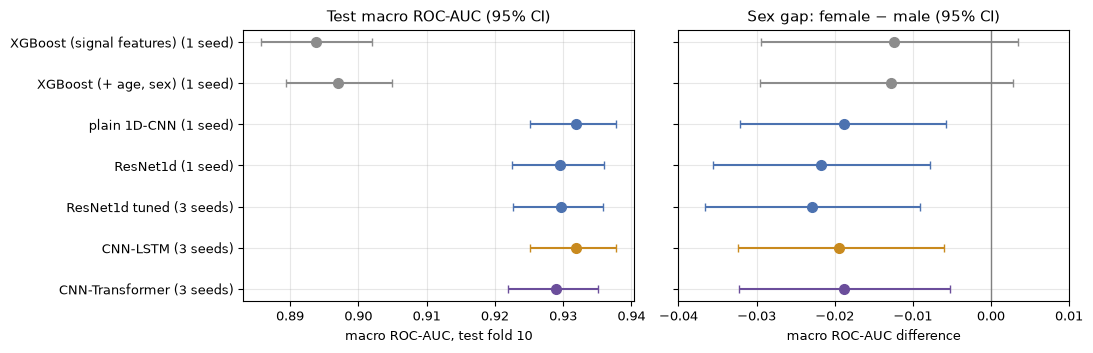

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
names = list(MODELS)[::-1]
yy = np.arange(len(names))
for a, (col, lo, hi, title, xlab) in zip(ax, (
        ('ROC-AUC', 'CI low', 'CI high', 'Test macro ROC-AUC (95% CI)', 'macro ROC-AUC, test fold 10'),
        ('gap F-M', 'gap low', 'gap high', 'Sex gap: female − male (95% CI)', 'macro ROC-AUC difference'))):
    c = comparison.loc[names]
    for y_, n in zip(yy, names):
        a.errorbar(c.loc[n, col], y_, xerr=[[c.loc[n, col] - c.loc[n, lo]], [c.loc[n, hi] - c.loc[n, col]]],
                   fmt='o', ms=7, capsize=3, color=FAMILY_COLORS[FAMILY[n]])
    a.set(title=title, xlabel=xlab)
ax[1].axvline(0, color='gray', lw=1)
ax[1].set_xticks(np.arange(-0.04, 0.0101, 0.01))
ax[0].set_yticks(yy, [f'{n} ({comparison.loc[n, "seeds"]:.0f} seed{"s" if comparison.loc[n, "seeds"] > 1 else ""})'
                      for n in names])
plt.tight_layout()
plt.savefig(FIG_DIR + 'w9_comparison.png', dpi=150)
plt.show()

## Задача 3. Интерпретация

Объясняется основная модель (CNN-LSTM, seed 42) и для сравнения свёрточная ResNet1d (настройки недели 5,
seed 42). Анализ — на всех MI-положительных записях теста. Запись 9 с разбивается на те же 7 окон по
2.5 с с шагом 1 с, что и при предсказании; карта каждого окна возвращается на ось времени записи, на
перекрытиях карты усредняются.

- **Карта внимания** — веса attention-pooling CNN-LSTM (62 шага по 40 мс). Веса общие для всех пяти
  выходов, то есть показывают, *какие участки модель собирает*, а не почему ставит именно MI.
- **Grad-CAM для MI** — градиент выхода MI по выходу свёрточной части (стебель CNN-LSTM, последний блок
  ResNet1d), взвешенная сумма каналов, отрицательное отсекается. Карта специфична для класса.
- **Вклад отведений** — |градиент × вход| выхода MI, сумма по времени для каждого отведения,
  нормировка на 1 внутри записи.

In [4]:
WIN, STEP = int(2.5 * FS), FS
X_mm = np.load(CACHE + 'X100_bp05-40_crop.npy', mmap_mode='r')
mi_rows = te[y_te[:, K_MI] == 1]
mi_sex = sex[mi_rows]
X_mi_mv = np.asarray(X_mm[mi_rows])  # мВ после фильтра, для R-пиков и рисунков
X_mi = torch.from_numpy(((X_mi_mv - LEAD_MEAN) / LEAD_STD).astype(np.float32))
T = X_mi.shape[1]
STARTS = list(range(0, T - WIN + 1, STEP))
T_COV = STARTS[-1] + WIN  # последние 0.5 с не попадают ни в одно окно — ни при предсказании, ни в картах
print(f'MI-положительных записей в тесте: {len(mi_rows)} (женщин {np.sum(mi_sex == "female")}); '
      f'окон на запись: {len(STARTS)}')

lstm = load_model(RUNS['cnn_lstm_w2.5_c128_lr0.001_s42'], RUNS['cnn_lstm_w2.5_c128_lr0.001_s42']['weights'])
resnet = load_model(RUNS['resnet1d_w2.5_c64-128-128_lr0.001_s42'],
                    RUNS['resnet1d_w2.5_c64-128-128_lr0.001_s42']['weights'])


def to_windows(x):  # (n, T, leads) -> (n * n_win, leads, WIN)
    return x.unfold(1, WIN, STEP).reshape(-1, x.shape[2], WIN)


def to_timeline(maps):  # (n, n_win, WIN) -> (n, T_COV): среднее карт окон на оси времени записи
    out, cnt = np.zeros((maps.shape[0], T_COV)), np.zeros(T_COV)
    for j, s in enumerate(STARTS):
        out[:, s:s + WIN] += maps[:, j]
        cnt[s:s + WIN] += 1
    return out / cnt


@torch.no_grad()
def predict(model, x, batch=256):
    out = []
    for i in range(0, len(x), batch):
        w = to_windows(x[i:i + batch])
        out.append(torch.sigmoid(model(w)).reshape(-1, len(STARTS), 5).mean(dim=1))
    return torch.cat(out).numpy()


saved = RUNS['cnn_lstm_w2.5_c128_lr0.001_s42']['s_test'][y_te[:, K_MI] == 1]
local = predict(lstm, X_mi)
print(f'проверка загрузки весов: корреляция с предсказаниями Colab {np.corrcoef(local.ravel(), saved.ravel())[0, 1]:.5f}, '
      f'макс. расхождение {np.abs(local - saved).max():.1e}')

MI-положительных записей в тесте: 550 (женщин 253); окон на запись: 7


проверка загрузки весов: корреляция с предсказаниями Colab 1.00000, макс. расхождение 3.2e-06


In [5]:
def explain(model, layer, x, k=K_MI, batch=64):
    """Grad-CAM класса k по выходу layer, вклад отведений |grad × input| и (если есть) веса внимания."""
    cams, leads, attn = [], [], []
    store = {}
    handle = layer.register_forward_hook(lambda m, i, o: store.update(act=o))
    for i in range(0, len(x), batch):
        w = to_windows(x[i:i + batch]).clone().requires_grad_(True)
        logit = model(w)[:, k]
        act = store['act']
        g_act, g_in = torch.autograd.grad(logit.sum(), [act, w])
        cam = F.relu((g_act.mean(dim=2, keepdim=True) * act).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=WIN, mode='linear', align_corners=False).squeeze(1)
        n = w.shape[0] // len(STARTS)
        cams.append(cam.detach().reshape(n, len(STARTS), WIN).numpy())
        leads.append((g_in * w).abs().sum(dim=2).detach().reshape(n, len(STARTS), -1).sum(dim=1).numpy())
        if getattr(model, 'pool', None) is not None:
            a = model.pool.weights.repeat_interleave(WIN // model.pool.weights.shape[1], dim=1)
            a = F.pad(a, (0, WIN - a.shape[1]), mode='replicate') if a.shape[1] < WIN else a
            attn.append(a.reshape(n, len(STARTS), WIN).numpy())
    handle.remove()
    lead_share = np.concatenate(leads)
    out = {'cam': to_timeline(np.concatenate(cams)), 'leads': lead_share / lead_share.sum(axis=1, keepdims=True)}
    if attn:
        out['attn'] = to_timeline(np.concatenate(attn))
    return out


EXPL = {'CNN-LSTM': explain(lstm, lstm.stem, X_mi), 'ResNet1d': explain(resnet, resnet.features, X_mi)}
print({k: {kk: v.shape for kk, v in d.items()} for k, d in EXPL.items()})

C:\Users\Zhumabek\projects\thesis-practice-part\.venv\Lib\site-packages\torch\nn\modules\conv.py:380: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\Convolution.cpp:1105.)
  return F.conv1d(


{'CNN-LSTM': {'cam': (550, 850), 'leads': (550, 12), 'attn': (550, 850)}, 'ResNet1d': {'cam': (550, 850), 'leads': (550, 12)}}


### Отражают ли карты работу модели? Тест удаления

Если Grad-CAM действительно указывает на участки, по которым модель ставит MI, то их «стирание» должно
снижать вероятность MI сильнее, чем стирание случайных участков той же длины. Стирание — замена
отрезков на 0 в нормированных единицах (среднее обучающих фолдов), 20 % длительности записи: отрезки
по 80 мс вокруг пиков карты против случайных отрезков.

In [6]:
DEL_FRAC, SEG = 0.20, 8


def top_segments_mask(sal, frac=DEL_FRAC, seg=SEG):
    n_seg = sal.shape[1] // seg
    seg_score = sal[:, :n_seg * seg].reshape(len(sal), n_seg, seg).sum(axis=2)
    k = int(round(frac * n_seg))
    top = np.argsort(-seg_score, axis=1)[:, :k]
    mask = np.zeros((len(sal), n_seg), bool)
    np.put_along_axis(mask, top, True, axis=1)
    return np.repeat(mask, seg, axis=1)


def random_segments_mask(n, rng, frac=DEL_FRAC, seg=SEG):
    n_seg = T_COV // seg
    k = int(round(frac * n_seg))
    mask = np.zeros((n, n_seg), bool)
    for i in range(n):
        mask[i, rng.choice(n_seg, k, replace=False)] = True
    return np.repeat(mask, seg, axis=1)


def masked_prob(model, mask):
    m = np.zeros((len(mask), T), bool)
    m[:, :mask.shape[1]] = mask
    x = X_mi.clone()
    x[torch.from_numpy(m)] = 0.0
    return predict(model, x)[:, K_MI]


rng = np.random.default_rng(SEED)
del_rows = []
for name, model in (('CNN-LSTM', lstm), ('ResNet1d', resnet)):
    p0 = predict(model, X_mi)[:, K_MI]
    p_top = masked_prob(model, top_segments_mask(EXPL[name]['cam']))
    p_rand = masked_prob(model, random_segments_mask(len(X_mi), rng))
    del_rows.append({'model': name, 'P(MI) original': p0.mean(), 'Grad-CAM top 20% erased': p_top.mean(),
                     'random 20% erased': p_rand.mean(),
                     'records where top drop > random drop, %': ((p0 - p_top) > (p0 - p_rand)).mean() * 100})
    if 'attn' in EXPL[name]:
        p_att = masked_prob(model, top_segments_mask(EXPL[name]['attn']))
        del_rows[-1]['attention top 20% erased'] = p_att.mean()
deletion = pd.DataFrame(del_rows).set_index('model')
print(deletion.round(3).to_string())

          P(MI) original  Grad-CAM top 20% erased  random 20% erased  records where top drop > random drop, %  attention top 20% erased
model                                                                                                                                  
CNN-LSTM           0.668                    0.560              0.696                                   87.091                     0.684
ResNet1d           0.633                    0.567              0.680                                   81.091                       NaN


### Куда смотрят карты: QRS и ST-T

R-пики ищутся по отведению II (`find_peaks`, минимум 300 мс между пиками). Окно QRS — ±80 мс вокруг
R-пика, окно ST-T — от 100 до 400 мс после него; именно там проявляются патологические зубцы Q и
смещение ST при инфаркте. Обогащение = доля карты в окне / доля времени, занятая окном; 1 — карта
распределена равномерно, больше 1 — модель смотрит туда чаще, чем случайно.

In [7]:
II = LEADS.index('II')


def segment_masks(x_mv):
    qrs, stt = np.zeros((len(x_mv), T), bool), np.zeros((len(x_mv), T), bool)
    ok = np.zeros(len(x_mv), bool)
    for i, rec in enumerate(x_mv):
        sig = rec[:, II] - np.median(rec[:, II])
        peaks, _ = find_peaks(np.abs(sig), distance=int(0.3 * FS), prominence=0.4 * np.ptp(sig))
        if len(peaks) < 3:
            continue
        ok[i] = True
        for p in peaks:
            qrs[i, max(p - 8, 0):p + 9] = True
            stt[i, p + 10:p + 41] = True
    return qrs[:, :T_COV], (stt & ~qrs)[:, :T_COV], ok


QRS, STT, R_OK = segment_masks(X_mi_mv)
print(f'R-пики найдены в {R_OK.sum()} из {len(R_OK)} записей')
print('записей с нулевой картой Grad-CAM: ' + ', '.join(f'{n} {(EXPL[n]["cam"].sum(axis=1) == 0).sum()}' for n in EXPL))


def enrichment(sal, mask):
    return (sal * mask).sum(axis=1) / sal.sum(axis=1) / mask.mean(axis=1)


enr_rows = []
for model_name, maps in (('CNN-LSTM', ('cam', 'attn')), ('ResNet1d', ('cam',))):
    for kind in maps:
        sal = EXPL[model_name][kind]
        valid = R_OK & (sal.sum(axis=1) > 0)  # Grad-CAM целиком нулевой, если градиент MI везде отрицателен
        for seg_name, mask in (('QRS', QRS[valid]), ('ST-T', STT[valid])):
            e = enrichment(sal[valid], mask)
            f, m = e[mi_sex[valid] == 'female'], e[mi_sex[valid] == 'male']
            enr_rows.append({'explanation': f'{model_name} {"Grad-CAM MI" if kind == "cam" else "attention"}',
                             'segment': seg_name, 'records': int(valid.sum()), 'median all': np.median(e),
                             'median female': np.median(f), 'median male': np.median(m),
                             'p (F vs M)': mannwhitneyu(f, m).pvalue})
enrich = pd.DataFrame(enr_rows)
print(enrich.round(3).to_string(index=False))

R-пики найдены в 518 из 550 записей
записей с нулевой картой Grad-CAM: CNN-LSTM 0, ResNet1d 0
         explanation segment  records  median all  median female  median male  p (F vs M)
CNN-LSTM Grad-CAM MI     QRS      518       1.749          1.636        1.853       0.001
CNN-LSTM Grad-CAM MI    ST-T      518       0.841          0.891        0.788       0.011
  CNN-LSTM attention     QRS      518       3.939          3.577        4.119       0.000
  CNN-LSTM attention    ST-T      518       0.157          0.212        0.117       0.001
ResNet1d Grad-CAM MI     QRS      518       2.072          1.792        2.301       0.001
ResNet1d Grad-CAM MI    ST-T      518       0.503          0.563        0.483       0.133


## Задача 4. Объяснения у мужчин и женщин

В году 1 на Cleveland модель опиралась у мужчин и женщин на разные признаки. Здесь аналог признака —
отведение: сравниваем средний профиль вклада отведений для MI у мужчин и женщин (CNN-LSTM и ResNet1d).

In [8]:
lead_rows = []
for name in EXPL:
    L = EXPL[name]['leads']
    f, m = L[mi_sex == 'female'], L[mi_sex == 'male']
    p = np.array([mannwhitneyu(f[:, j], m[:, j]).pvalue for j in range(len(LEADS))])
    prof = pd.DataFrame({'female': f.mean(0), 'male': m.mean(0), 'female - male': f.mean(0) - m.mean(0),
                         'p': p, 'significant (Bonferroni)': p < 0.05 / len(LEADS)}, index=LEADS)
    rho = spearmanr(f.mean(0), m.mean(0)).correlation
    print(f'\n{name}: доля вклада отведений в выход MI (среднее), Спирмен профилей F/M = {rho:.3f}')
    print(prof.round(4).to_string())
    top_f = prof.female.sort_values(ascending=False).index[:3].tolist()
    top_m = prof.male.sort_values(ascending=False).index[:3].tolist()
    print(f'топ-3 отведения: женщины {top_f}, мужчины {top_m}')
    lead_rows.append(prof.assign(model=name))
lead_profiles = pd.concat(lead_rows)


CNN-LSTM: доля вклада отведений в выход MI (среднее), Спирмен профилей F/M = 0.797
     female    male  female - male       p  significant (Bonferroni)
I    0.0728  0.0689         0.0039  0.0118                     False
II   0.0795  0.0766         0.0029  0.1634                     False
III  0.0840  0.0805         0.0035  0.2254                     False
AVR  0.0855  0.0810         0.0044  0.0423                     False
AVL  0.0871  0.0796         0.0075  0.0181                     False
AVF  0.0908  0.0911        -0.0003  0.8891                     False
V1   0.0974  0.0934         0.0040  0.3015                     False
V2   0.1060  0.1020         0.0040  0.5469                     False
V3   0.0763  0.0813        -0.0049  0.0114                     False
V4   0.0631  0.0768        -0.0136  0.0000                      True
V5   0.0722  0.0786        -0.0064  0.0001                      True
V6   0.0854  0.0902        -0.0049  0.0654                     False
топ-3 отведения: же

### Проверка: не объясняется ли разница структурой подтипов

У женщин меньше нижних и больше передних инфарктов (неделя 6), а подтип сам меняет, какие отведения
информативны. Поэтому сравнение по полу повторяется внутри подтипов IMI и AMI.

In [9]:
import ast

DATA_PATH = os.path.dirname(glob.glob('**/ptbxl_database.csv', recursive=True)[0]) + os.sep
db = pd.read_csv(DATA_PATH + 'ptbxl_database.csv', index_col='ecg_id')
scp = pd.read_csv(DATA_PATH + 'scp_statements.csv', index_col=0)
mi_sub = scp[(scp.diagnostic == 1) & (scp.diagnostic_class == 'MI')].diagnostic_subclass
codes = db.scp_codes.iloc[mi_rows].apply(ast.literal_eval)
subtype = codes.apply(lambda c: (lambda s: s[0] if len(s) == 1 else 'mixed')(sorted({mi_sub[k] for k in c
                                                                                      if k in mi_sub.index}))).to_numpy()
V45 = [LEADS.index('V4'), LEADS.index('V5')]
cam_valid = R_OK & (EXPL['CNN-LSTM']['cam'].sum(axis=1) > 0)
qrs_enr = np.full(len(mi_rows), np.nan)
qrs_enr[cam_valid] = enrichment(EXPL['CNN-LSTM']['cam'][cam_valid], QRS[cam_valid])
strat_rows = []
for st in ('IMI', 'AMI'):
    for name in EXPL:
        v45 = EXPL[name]['leads'][:, V45].sum(axis=1)
        f, m = (subtype == st) & (mi_sex == 'female'), (subtype == st) & (mi_sex == 'male')
        row = {'subtype': st, 'model': name, 'n female': int(f.sum()), 'n male': int(m.sum()),
               'V4+V5 share female': v45[f].mean(), 'V4+V5 share male': v45[m].mean(),
               'p V4+V5': mannwhitneyu(v45[f], v45[m]).pvalue}
        if name == 'CNN-LSTM':
            ef, em = qrs_enr[f & cam_valid], qrs_enr[m & cam_valid]
            row.update({'QRS enrichment female': np.median(ef), 'QRS enrichment male': np.median(em),
                        'p QRS': mannwhitneyu(ef, em).pvalue})
        strat_rows.append(row)
by_subtype = pd.DataFrame(strat_rows)
print(by_subtype.round(4).to_string(index=False))

subtype    model  n female  n male  V4+V5 share female  V4+V5 share male  p V4+V5  QRS enrichment female  QRS enrichment male  p QRS
    IMI CNN-LSTM        89     140              0.1205            0.1521   0.0000                 1.6085               1.8643 0.0511
    IMI ResNet1d        89     140              0.1281            0.1586   0.0000                    NaN                  NaN    NaN
    AMI CNN-LSTM       102     101              0.1490            0.1589   0.0491                 1.5254               1.7849 0.0216
    AMI ResNet1d       102     101              0.1493            0.1658   0.0236                    NaN                  NaN    NaN


In [10]:
pred_mi = local[:, K_MI]
th_mi = screening_thresholds(y_va, RUNS['cnn_lstm_w2.5_c128_lr0.001_s42']['s_val'])[K_MI]
L = EXPL['CNN-LSTM']['leads']
grp = {'female detected': (mi_sex == 'female') & (pred_mi >= th_mi),
       'female missed': (mi_sex == 'female') & (pred_mi < th_mi),
       'male detected': (mi_sex == 'male') & (pred_mi >= th_mi),
       'male missed': (mi_sex == 'male') & (pred_mi < th_mi)}
miss = pd.DataFrame({g: L[m].mean(0) for g, m in grp.items()}, index=LEADS)
print('CNN-LSTM, вклад отведений: найденные и пропущенные MI (общий порог):')
print(pd.Series({g: int(m.sum()) for g, m in grp.items()}).to_string())
print(miss.round(4).to_string())
print('\nдоля нижних (II, III, aVF) и передних (V1–V3) отведений:')
print(pd.DataFrame({'inferior': miss.loc[['II', 'III', 'AVF']].sum(), 'anterior': miss.loc[['V1', 'V2', 'V3']].sum()})
      .round(3).to_string())

CNN-LSTM, вклад отведений: найденные и пропущенные MI (общий порог):
female detected    226
female missed       27
male detected      274
male missed         23
     female detected  female missed  male detected  male missed
I             0.0720         0.0790         0.0685       0.0737
II            0.0782         0.0904         0.0761       0.0831
III           0.0832         0.0909         0.0806       0.0794
AVR           0.0846         0.0924         0.0802       0.0909
AVL           0.0857         0.0986         0.0795       0.0804
AVF           0.0902         0.0954         0.0914       0.0874
V1            0.0985         0.0882         0.0943       0.0825
V2            0.1073         0.0948         0.1028       0.0924
V3            0.0777         0.0654         0.0810       0.0845
V4            0.0640         0.0553         0.0768       0.0764
V5            0.0730         0.0655         0.0791       0.0720
V6            0.0855         0.0841         0.0896       0.0974

доля н

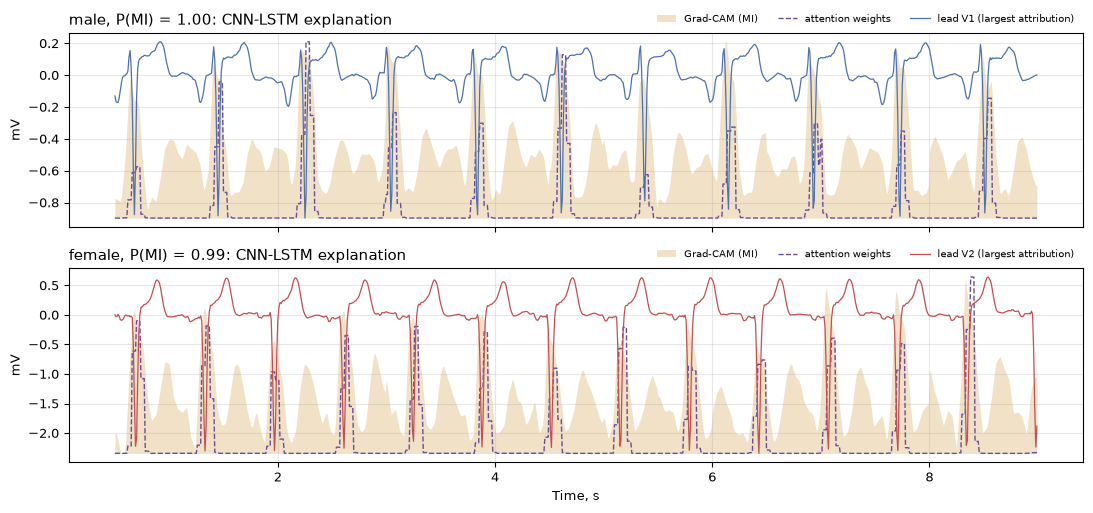

In [11]:
def pick_example(sex_label):
    cand = np.where((mi_sex == sex_label) & (pred_mi >= th_mi) & R_OK)[0]
    return cand[np.argmax(pred_mi[cand])]


fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
t_axis = (np.arange(T_COV) + int(0.5 * FS)) / FS
for a, s in zip(ax, ('male', 'female')):
    i = pick_example(s)
    cam = EXPL['CNN-LSTM']['cam'][i] / EXPL['CNN-LSTM']['cam'][i].max()
    att = EXPL['CNN-LSTM']['attn'][i] / EXPL['CNN-LSTM']['attn'][i].max()
    lead = LEADS[int(np.argmax(EXPL['CNN-LSTM']['leads'][i]))]
    sig = X_mi_mv[i, :T_COV, LEADS.index(lead)]
    lo, hi = sig.min(), sig.max()
    a.fill_between(t_axis, lo, lo + cam * (hi - lo), color='#C98A1E', alpha=0.25, lw=0, label='Grad-CAM (MI)')
    a.plot(t_axis, lo + att * (hi - lo), color='#6B4E9B', lw=1, ls='--', label='attention weights')
    a.plot(t_axis, sig, color=SEX_COLORS[s], lw=0.9, label=f'lead {lead} (largest attribution)')
    a.set_ylabel('mV')
    a.set_title(f'{s}, P(MI) = {pred_mi[i]:.2f}: CNN-LSTM explanation', loc='left')
    a.legend(fontsize=7, loc='lower right', bbox_to_anchor=(1, 1.0), ncol=3, frameon=False)
ax[-1].set_xlabel('Time, s')
plt.tight_layout()
plt.savefig(FIG_DIR + 'w9_maps.png', dpi=150)
plt.show()

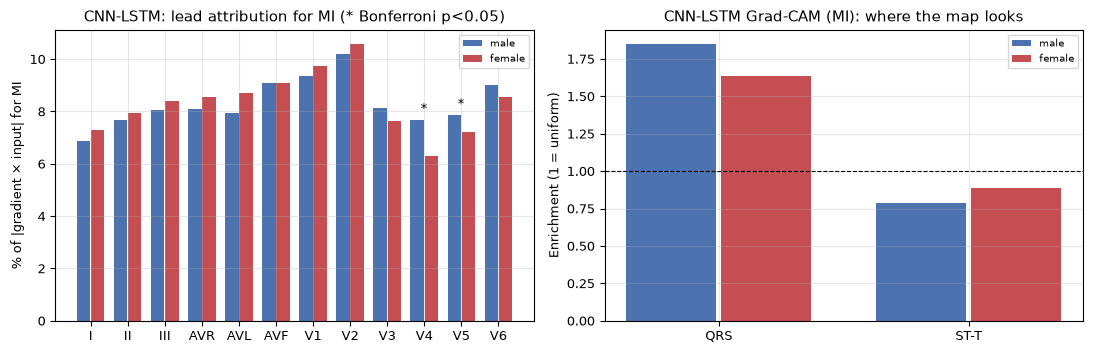

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
prof = lead_profiles[lead_profiles.model == 'CNN-LSTM']
x = np.arange(len(LEADS))
for k, s in enumerate(('male', 'female')):
    ax[0].bar(x + (k - 0.5) * 0.38, prof[s] * 100, 0.36, color=SEX_COLORS[s], label=s)
for j in np.where(prof['significant (Bonferroni)'])[0]:
    ax[0].annotate('*', (x[j], max(prof.male.iloc[j], prof.female.iloc[j]) * 100 + 0.3), ha='center')
ax[0].set_xticks(x, LEADS)
ax[0].set(ylabel='% of |gradient × input| for MI', title='CNN-LSTM: lead attribution for MI (* Bonferroni p<0.05)')
ax[0].legend(fontsize=7)

sub = enrich[enrich.explanation == 'CNN-LSTM Grad-CAM MI'].set_index('segment')
xs = np.arange(len(sub))
for k, s in enumerate(('male', 'female')):
    ax[1].bar(xs + (k - 0.5) * 0.38, sub[f'median {s}'], 0.36, color=SEX_COLORS[s], label=s)
ax[1].axhline(1, color='black', ls='--', lw=0.8)
ax[1].set_xticks(xs, sub.index)
ax[1].set(ylabel='Enrichment (1 = uniform)', title='CNN-LSTM Grad-CAM (MI): where the map looks')
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG_DIR + 'w9_leads_sex.png', dpi=150)
plt.show()

In [13]:
json.dump({'comparison': comparison.reset_index().to_dict('records'),
           'vs_main': vs_main.reset_index().to_dict('records'),
           'deletion': deletion.reset_index().to_dict('records'),
           'enrichment': enrich.to_dict('records')},
          open(CACHE + 'w9_summary.json', 'w'), indent=1, default=float)
print('сохранено: w9_summary.json и 3 рисунка w9_*.png')

сохранено: w9_summary.json и 3 рисунка w9_*.png


## Выводы недели 9

**Глубокие модели значимо лучше классической.** На тестовом фолде 10 все нейросети — 0.929–0.932
macro ROC-AUC, XGBoost на признаках сигнала — 0.894–0.897; разность с CNN-LSTM −0.035 [−0.040; −0.029] у
лучшего варианта XGBoost. По PR-AUC разрыв ещё больше: 0.834 против 0.764. При пороге скрининга
(чувствительность ≈ 0.89 у всех) CNN-LSTM даёт специфичность 0.809 против 0.716, precision 0.597 против
0.504, F1 0.704 против 0.629, accuracy 0.831 против 0.757.

**Между нейросетями разница в пределах шума.** CNN-LSTM, простая 1D-CNN и обе ResNet1d неразличимы
(|Δ| ≤ 0.0023, интервалы включают 0); значимо отстаёт только CNN-Transformer (−0.0030 [−0.0045; −0.0014]).

**Разрыв по полу у нейросетей больше, чем у XGBoost** (macro −0.019…−0.023 против −0.012…−0.013, у XGBoost
незначимо), но не потому, что женщин они распознают хуже: CNN-LSTM у женщин (0.922) точнее, чем XGBoost у
мужчин (0.904). Нейросети выигрывают у обоих полов, у мужчин — больше.

**Grad-CAM отражает работу модели, карты внимания — нет.** Стирание 20 % записи в местах максимума
Grad-CAM для MI снижает среднюю вероятность MI у CNN-LSTM с 0.668 до 0.560, стирание случайных 20 % — не
снижает (0.696); сильнее случайного — в 87 % записей (ResNet1d: 0.633 → 0.567 против 0.680, 81 %). Веса
attention-pooling общие для всех классов: их максимумы почти целиком на QRS (обогащение 3.9), а стирание
этих участков на MI почти не влияет (0.684). Для объяснения конкретного диагноза годится Grad-CAM, а не
веса внимания.

**Куда смотрит модель при MI.** Grad-CAM сосредоточен на комплексах QRS (обогащение 1.75 у CNN-LSTM, 2.07
у ResNet1d), а сегмент ST-T получает меньше равномерной доли (0.84 и 0.50). Это согласуется с тем, что
в PTB-XL преобладают сформировавшиеся инфаркты, распознаваемые по патологическому зубцу Q и форме QRS, а не
по подъёму ST.

**Объяснения у мужчин и женщин различаются — мотив года 1 воспроизводится на сырых ЭКГ.** Для MI у женщин
модель меньше опирается на V4 и V5 (CNN-LSTM: 6.3 % и 7.2 % вклада против 7.7 % и 7.9 % у мужчин; значимо
с поправкой Бонферрони у обеих моделей), Grad-CAM у женщин меньше сосредоточен на QRS (1.64 против 1.85,
p = 0.001) и больше на ST-T (0.89 против 0.79, p = 0.011). Различие не объясняется структурой подтипов:
внутри нижних инфарктов доля V4+V5 — 0.121 у женщин против 0.152 у мужчин (p < 0.0001), внутри передних —
0.149 против 0.159 (p = 0.049). Корреляция профилей вклада отведений мужчин и женщин — 0.80 (CNN-LSTM) и 0.63
(ResNet1d), тогда как у XGBoost на признаках сигнала TreeSHAP-ранжирование совпадало почти полностью
(0.991, неделя 4). Признаковая модель асимметрию скрывает, нейросеть на сырых сигналах её показывает.

## Рекомендации по выбору метода

| Задача | Рекомендация | Почему |
|---|---|---|
| Максимальное качество | CNN-LSTM или простая 1D-CNN | лучшие ROC-AUC / PR-AUC, разница между ними в пределах шума |
| Прототип СППВР | CNN-LSTM | качество, наименьший разброс по seed, обучение 1.2 мин, 505 тыс. параметров |
| Объяснение диагноза | Grad-CAM + вклад отведений | проходит тест удаления; веса внимания — нет |
| Табличные признаки / малые данные | XGBoost + TreeSHAP | как в году 1; на сырых ЭКГ проигрывает 0.035 AUC |
| Не рекомендуется | Transformer без предобучения, подбор ширины ResNet1d | не дают прироста при большей стоимости |

## План на неделю 10

1. Выводы по итогам практики и отчёт по исследовательской практике (по задачам календарного плана).
2. Отчёт НИРМ-3 по задачам ИПРМ за 4-й триместр.